# Patient wait time: EDA and feature engineering

Explore gender, age, race, referral and admission status in relation to Patient Waittime. Source: `Kaggle_HealthData_Cleaned.csv` from the cleaning notebook. Place that CSV beside this notebook and run all cells. Patient Waittime is measured in minutes, as confirmed by the user. All wait-time statistics and visualizations use minutes. These are descriptive associations and do not establish causes. Download cells below each figure provide PNG links in Jupyter, including when viewed remotely.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

source = Path("Kaggle_HealthData_Cleaned.csv")
df = pd.read_csv(source, dtype={"Patient Id": "string"}, keep_default_na=False)
df = df.replace(r"^\s*$", pd.NA, regex=True)
df["Patient Admission Date"] = pd.to_datetime(df["Patient Admission Date"], format="%Y-%m-%d", errors="raise")
df["Patient Admission Time"] = pd.to_datetime(df["Patient Admission Time"], format="%H:%M:%S", errors="raise").dt.time
plot_dir = Path("eda_visualizations")
plot_dir.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", palette="colorblind")
print(f"{len(df):,} rows; {len(df.columns)} columns")
df.head()

9,216 rows; 10 columns


,Patient Id,Patient Admission Date,Patient Admission Time,pt name,Patient Gender,Patient Age,Patient Race,Department Referral,Patient Admission Flag,Patient Waittime
0,780966113,2024-09-09,09:25:00,W. Breede,Female,63,African American,None,Not Admission,32
1,714356722,2024-09-09,16:42:00,Y. Baldetti,Male,31,Asian,Orthopedics,Not Admission,22
2,571853714,2024-09-09,00:14:00,M. Semerad,Male,75,White,General Practice,Not Admission,16
3,404439499,2024-09-09,20:33:00,K. Blaydes,Male,79,African American,General Practice,Admission,38
4,552515855,2024-09-09,19:25:00,F. Dickerson,Female,24,African American,None,Admission,36


## Data quality and analysis setup

Label the 17 `Femaleemale` entries as `unknown`, preserving the original category in a separate column. The recorded gender is unclear, so we do not assume the patient’s gender. Literal `None` under Department Referral is a valid no-referral category. No records are dropped. No outliers are removed without a domain rule.

In [2]:
df["Gender original"] = df["Patient Gender"]
typo_count = df["Patient Gender"].eq("Femaleemale").sum()
df["Patient Gender"] = df["Patient Gender"].replace({"Femaleemale": "unknown"})
for col in ["Patient Age", "Patient Waittime"]:
    df[col] = pd.to_numeric(df[col], errors="raise")
print(f"Corrected {typo_count} Femaleemale entries to unknown because the gender is unclear; no gender is assumed.")
print(f"Exact duplicate rows: {df.duplicated().sum()}")
print(f"Repeated patient IDs: {df['Patient Id'].duplicated().sum()}")
df.isna().sum().rename("Missing values").to_frame()

Corrected 17 Femaleemale entries to unknown because the gender is unclear; no gender is assumed.
Exact duplicate rows: 0
Repeated patient IDs: 0


,Missing values
Patient Id,0
Patient Admission Date,0
Patient Admission Time,0
pt name,0
Patient Gender,0
Patient Age,0
Patient Race,0
Department Referral,0
Patient Admission Flag,0
Patient Waittime,0


In [3]:
df[["Patient Age", "Patient Waittime"]].describe()

,Patient Age,Patient Waittime
count,9216.000000,9216.000000
mean,39.855143,35.259874
std,22.755125,14.735323
min,1.000000,10.000000
25%,20.000000,23.000000
50%,39.000000,35.000000
75%,60.000000,48.000000
max,79.000000,60.000000


## Overall wait-time distribution

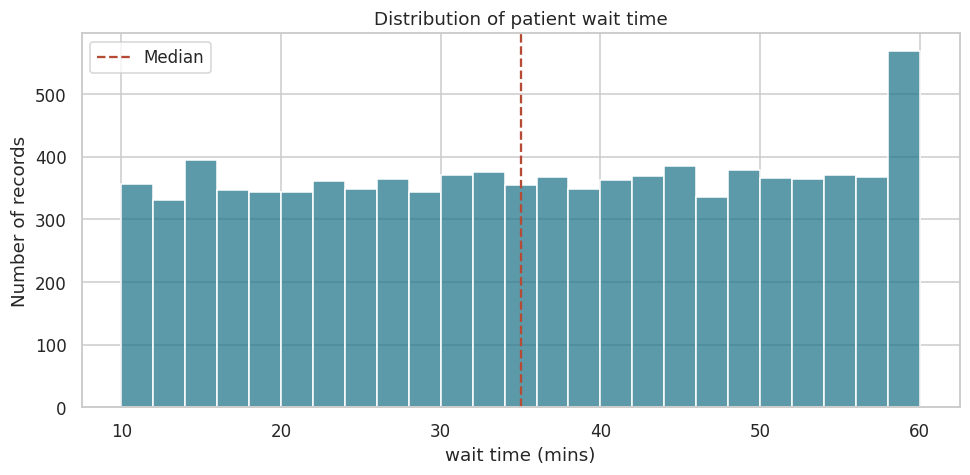

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(data=df, x="Patient Waittime", bins=25, ax=ax, color="#26778C")
ax.axvline(df["Patient Waittime"].median(), color="#B64B35", linestyle="--", label="Median")
ax.set(title="Distribution of patient wait time", xlabel="wait time (mins)", ylabel="Number of records")
ax.legend()
fig.tight_layout()
fig.savefig(plot_dir / "01_wait_distribution.png", dpi=180, bbox_inches="tight")
plt.show()

**Download this visualization** — run the cell and click its link.

<Download link>
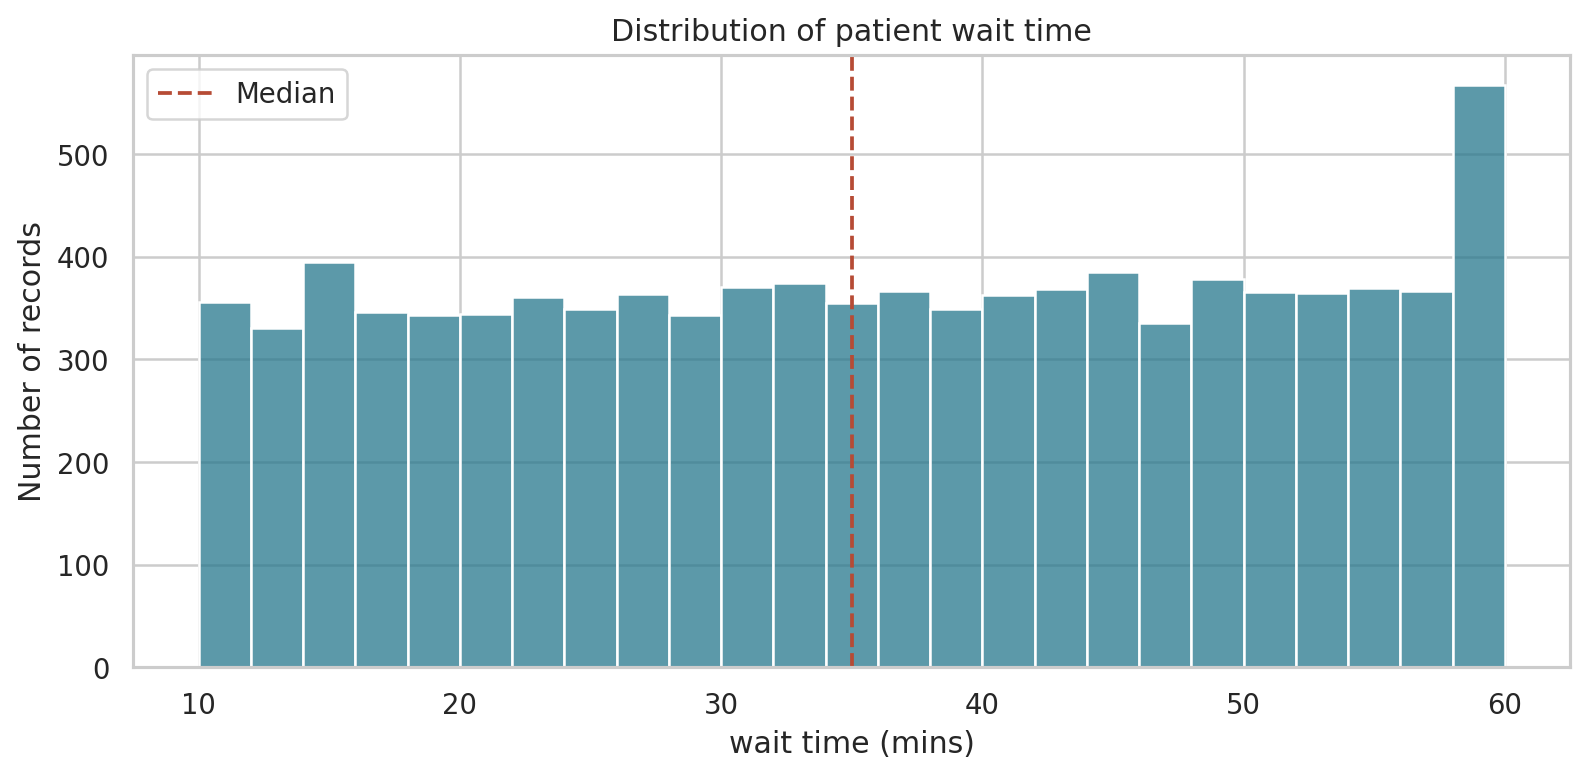

In [5]:
from IPython.display import HTML
import base64
image_path = plot_dir / "01_wait_distribution.png"
encoded = base64.b64encode(image_path.read_bytes()).decode("ascii")
HTML(f'<a download="{image_path.name}" href="data:image/png;base64,{encoded}">Download {image_path.name}</a>')

In [6]:
def wait_summary(column):
    return (df.groupby(column, observed=True, dropna=False)["Patient Waittime"]
            .agg(n="size", mean="mean", median="median", std="std", minimum="min", maximum="max")
            .round(2))

def category_plot(column, title, filename):
    order = df.groupby(column, observed=True)["Patient Waittime"].median().sort_values().index
    fig, ax = plt.subplots(figsize=(10, max(4, len(order)*0.55)))
    sns.boxplot(data=df, y=column, x="Patient Waittime", order=order, color="#91C7D0", ax=ax)
    ax.set(title=title, xlabel="wait time (mins)", ylabel="")
    fig.tight_layout()
    fig.savefig(plot_dir / filename, dpi=180, bbox_inches="tight")
    plt.show()

# Box: middle 50%; line: median; whiskers: 1.5 × IQR; points: beyond whiskers.

## Gender and wait time

In [7]:
wait_summary('Patient Gender')

,n,mean,median,std,minimum,maximum
Patient Gender,,,,,,
Female,4470,35.10,35.0,14.67,10,60
Male,4729,35.41,36.0,14.79,10,60
unknown,17,35.35,33.0,16.13,12,59


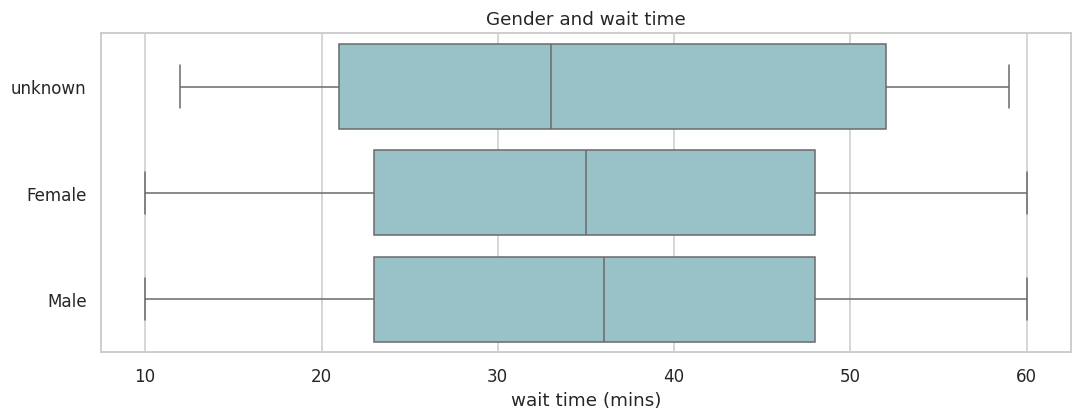

In [8]:
category_plot('Patient Gender', 'Gender and wait time', '02_gender_wait.png')

**Download this visualization** — run the cell and click its link.

<Download link>
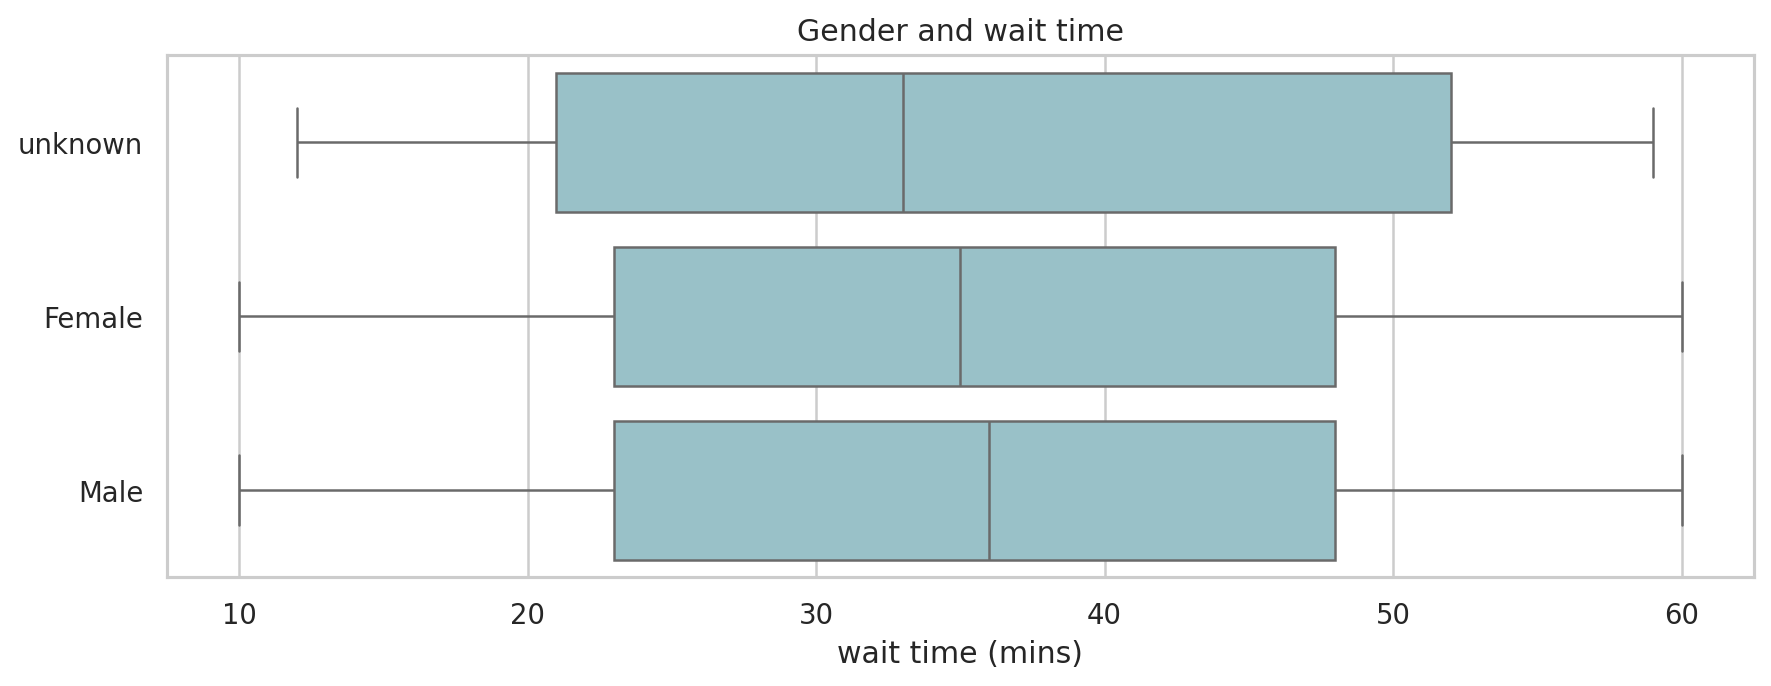

In [9]:
from IPython.display import HTML
import base64
image_path = plot_dir / "02_gender_wait.png"
encoded = base64.b64encode(image_path.read_bytes()).decode("ascii")
HTML(f'<a download="{image_path.name}" href="data:image/png;base64,{encoded}">Download {image_path.name}</a>')

## Age and wait time

The scatter plot shows individual records with transparency; age-band boxplots make distributions easier to compare. Pearson correlation captures linear association; Spearman captures monotonic association. Bands are descriptive and do not imply clinical cutoffs.

In [10]:
age_bins = [0, 17, 34, 49, 64, np.inf]
age_labels = ["0–17", "18–34", "35–49", "50–64", "65+"]
df["Age group"] = pd.cut(df["Patient Age"], bins=age_bins, labels=age_labels)
print("Pearson correlation:", round(df["Patient Age"].corr(df["Patient Waittime"]), 4))
print("Spearman correlation:", round(df["Patient Age"].rank().corr(df["Patient Waittime"].rank()), 4))
wait_summary("Age group")

Pearson correlation: -0.0056
Spearman correlation: -0.0056


,n,mean,median,std,minimum,maximum
Age group,,,,,,
0–17,1971,35.46,36.0,14.69,10,60
18–34,2019,35.31,36.0,14.72,10,60
35–49,1768,35.39,36.0,14.73,10,60
50–64,1722,34.95,35.0,14.99,10,60
65+,1736,35.15,35.0,14.56,10,60


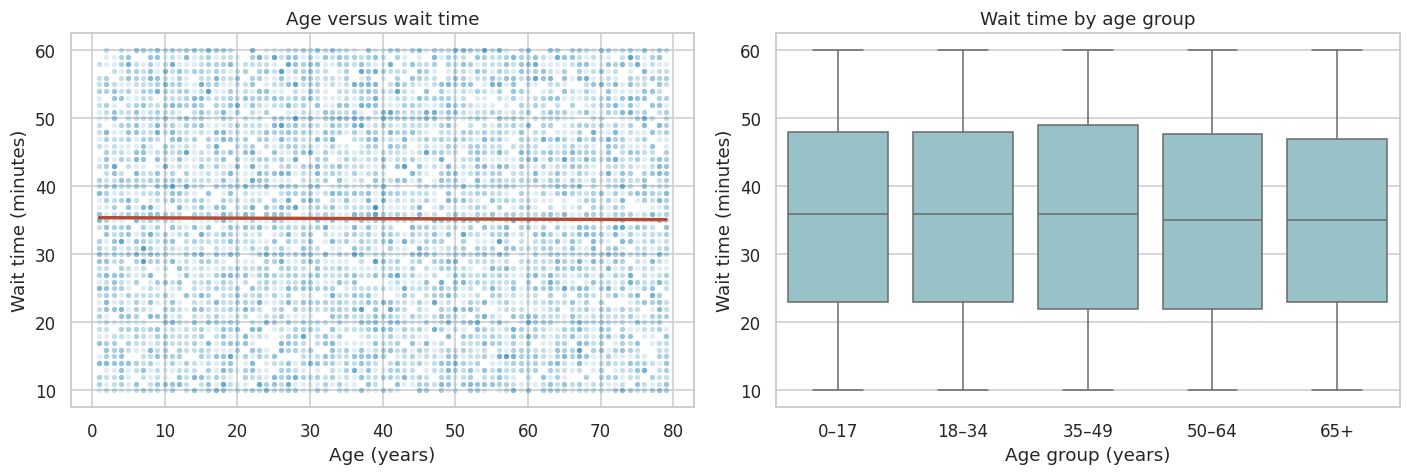

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(data=df, x="Patient Age", y="Patient Waittime", alpha=0.12, s=12, linewidth=0, ax=axes[0])
sns.regplot(data=df, x="Patient Age", y="Patient Waittime", scatter=False, ci=None, color="#B64B35", ax=axes[0])
sns.boxplot(data=df, x="Age group", y="Patient Waittime", color="#91C7D0", ax=axes[1])
axes[0].set(title="Age versus wait time", xlabel="Age (years)", ylabel="Wait time (minutes)")
axes[1].set(title="Wait time by age group", xlabel="Age group (years)", ylabel="Wait time (minutes)")
fig.tight_layout()
fig.savefig(plot_dir / "03_age_wait.png", dpi=180, bbox_inches="tight")
plt.show()

**Download this visualization** — run the cell and click its link.

<Download link>
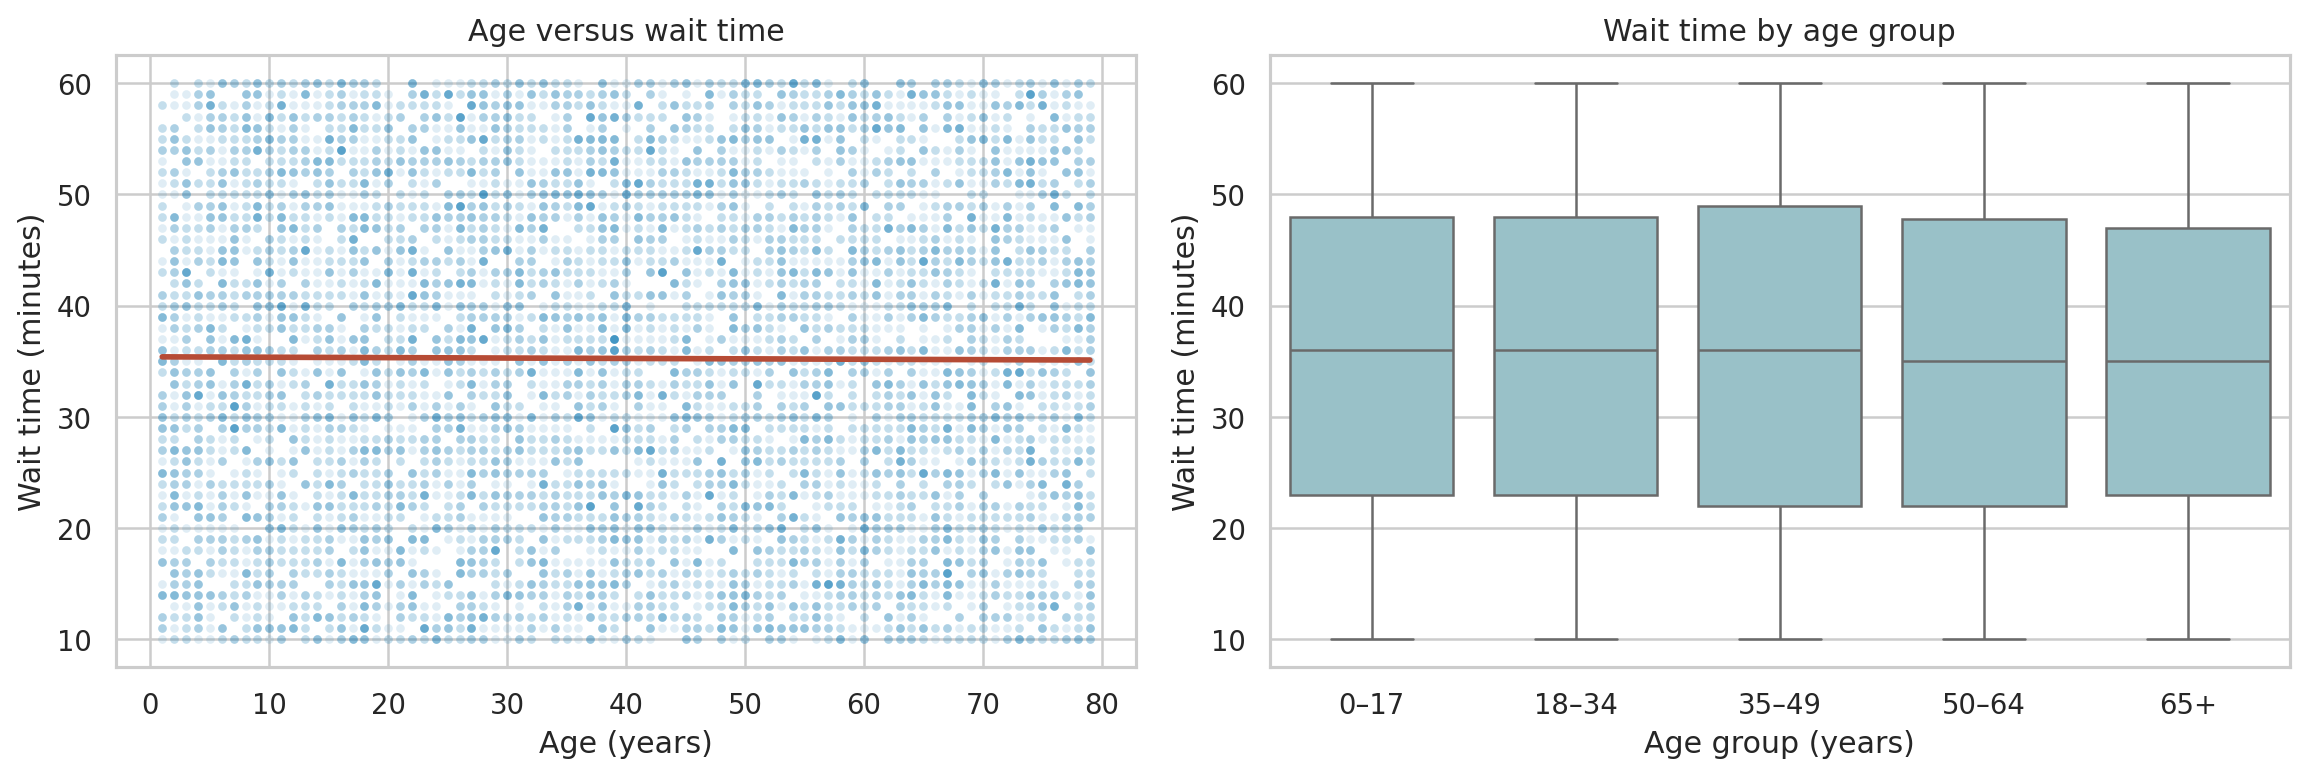

In [12]:
from IPython.display import HTML
import base64
image_path = plot_dir / "03_age_wait.png"
encoded = base64.b64encode(image_path.read_bytes()).decode("ascii")
HTML(f'<a download="{image_path.name}" href="data:image/png;base64,{encoded}">Download {image_path.name}</a>')

## Race and wait time

In [13]:
wait_summary('Patient Race')

,n,mean,median,std,minimum,maximum
Patient Race,,,,,,
African American,1951,35.61,36.0,14.55,10,60
Asian,1060,35.27,35.0,15.15,10,60
Declined to Identify,1030,34.94,35.0,14.60,10,60
Native American/Alaska Native,498,35.69,36.0,14.39,10,60
Pacific Islander,549,34.65,34.0,14.70,10,60
Two or More Races,1557,35.36,36.0,14.80,10,60
White,2571,35.11,35.0,14.80,10,60


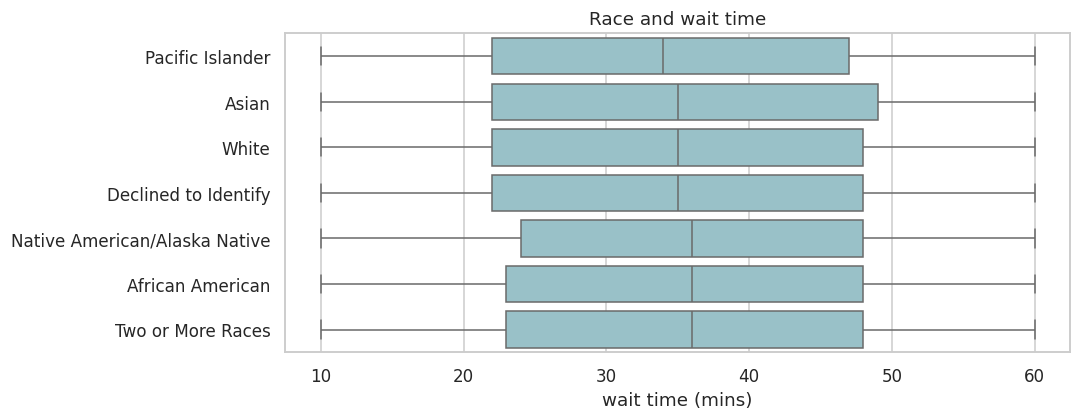

In [14]:
category_plot('Patient Race', 'Race and wait time', '04_race_wait.png')

**Download this visualization** — run the cell and click its link.

<Download link>
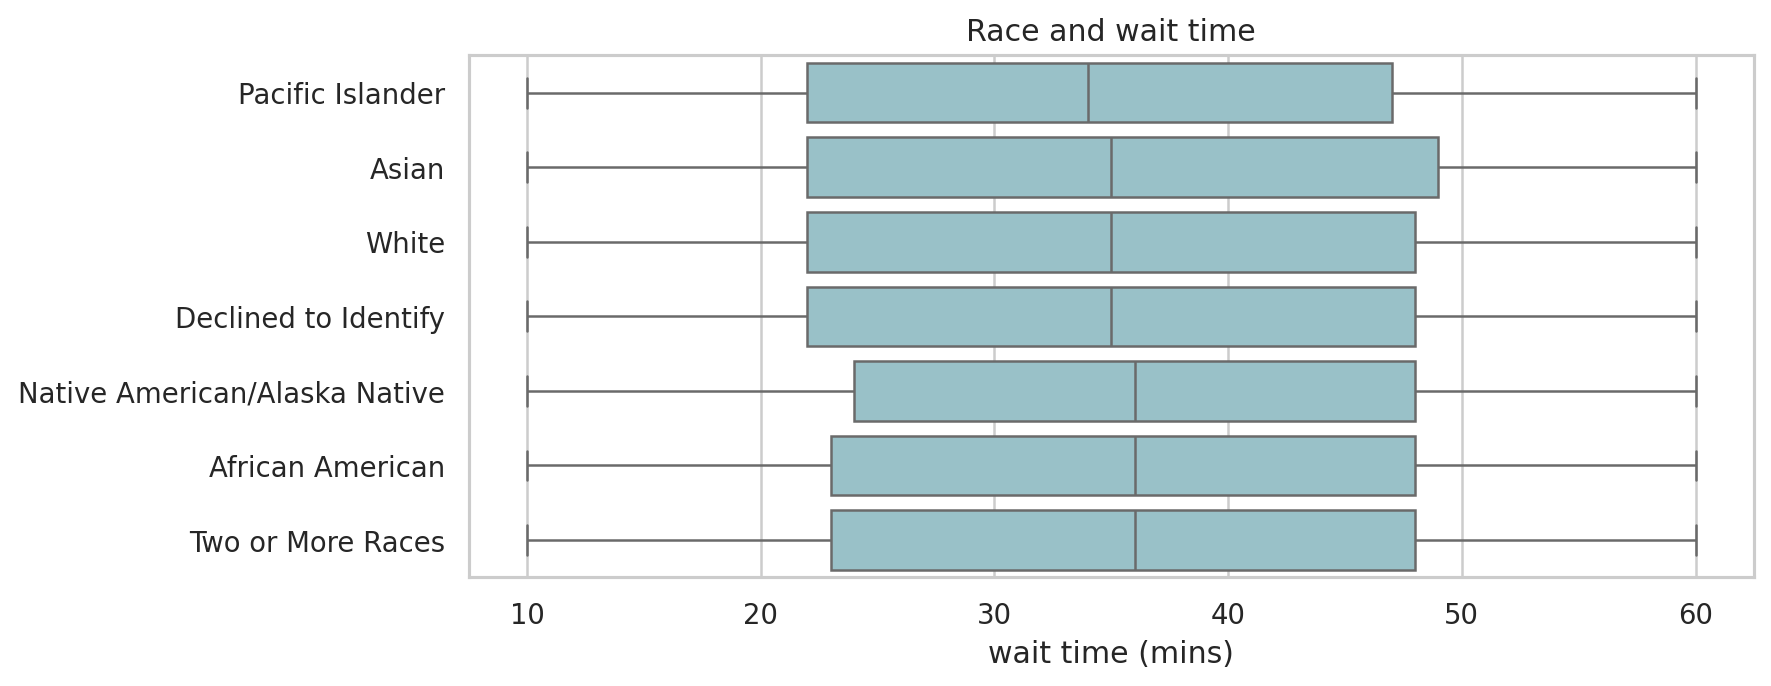

In [15]:
from IPython.display import HTML
import base64
image_path = plot_dir / "04_race_wait.png"
encoded = base64.b64encode(image_path.read_bytes()).decode("ascii")
HTML(f'<a download="{image_path.name}" href="data:image/png;base64,{encoded}">Download {image_path.name}</a>')

## Referral department and wait time

In [16]:
wait_summary('Department Referral')

,n,mean,median,std,minimum,maximum
Department Referral,,,,,,
Cardiology,248,35.35,35.0,15.47,10,60
Gastroenterology,178,35.83,36.0,14.66,10,60
General Practice,1840,34.91,35.0,14.98,10,60
Neurology,193,36.80,38.0,14.66,10,60
None,5400,35.29,35.0,14.62,10,60
Orthopedics,995,34.98,34.0,14.82,10,60
Physiotherapy,276,36.57,38.5,14.62,10,60
Renal,86,34.70,35.0,14.42,10,60


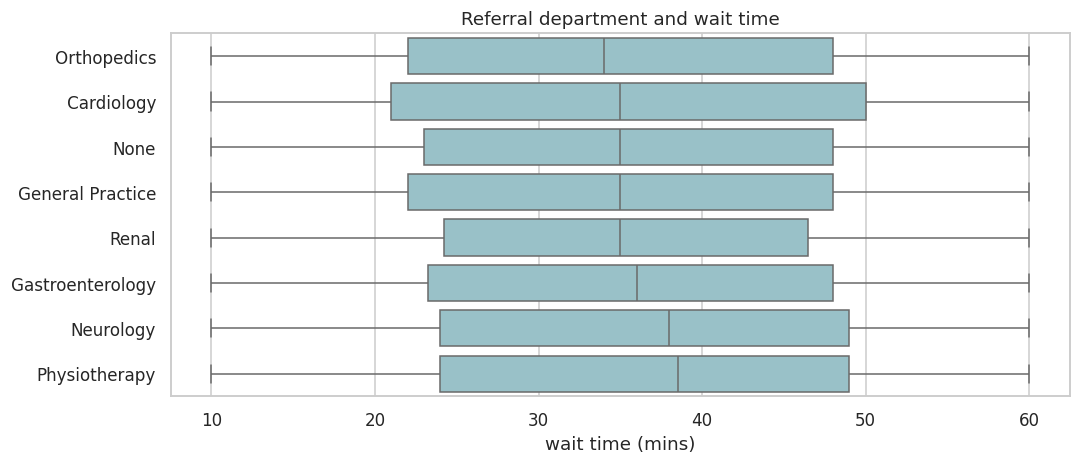

In [17]:
category_plot('Department Referral', 'Referral department and wait time', '05_referral_wait.png')

**Download this visualization** — run the cell and click its link.

<Download link>
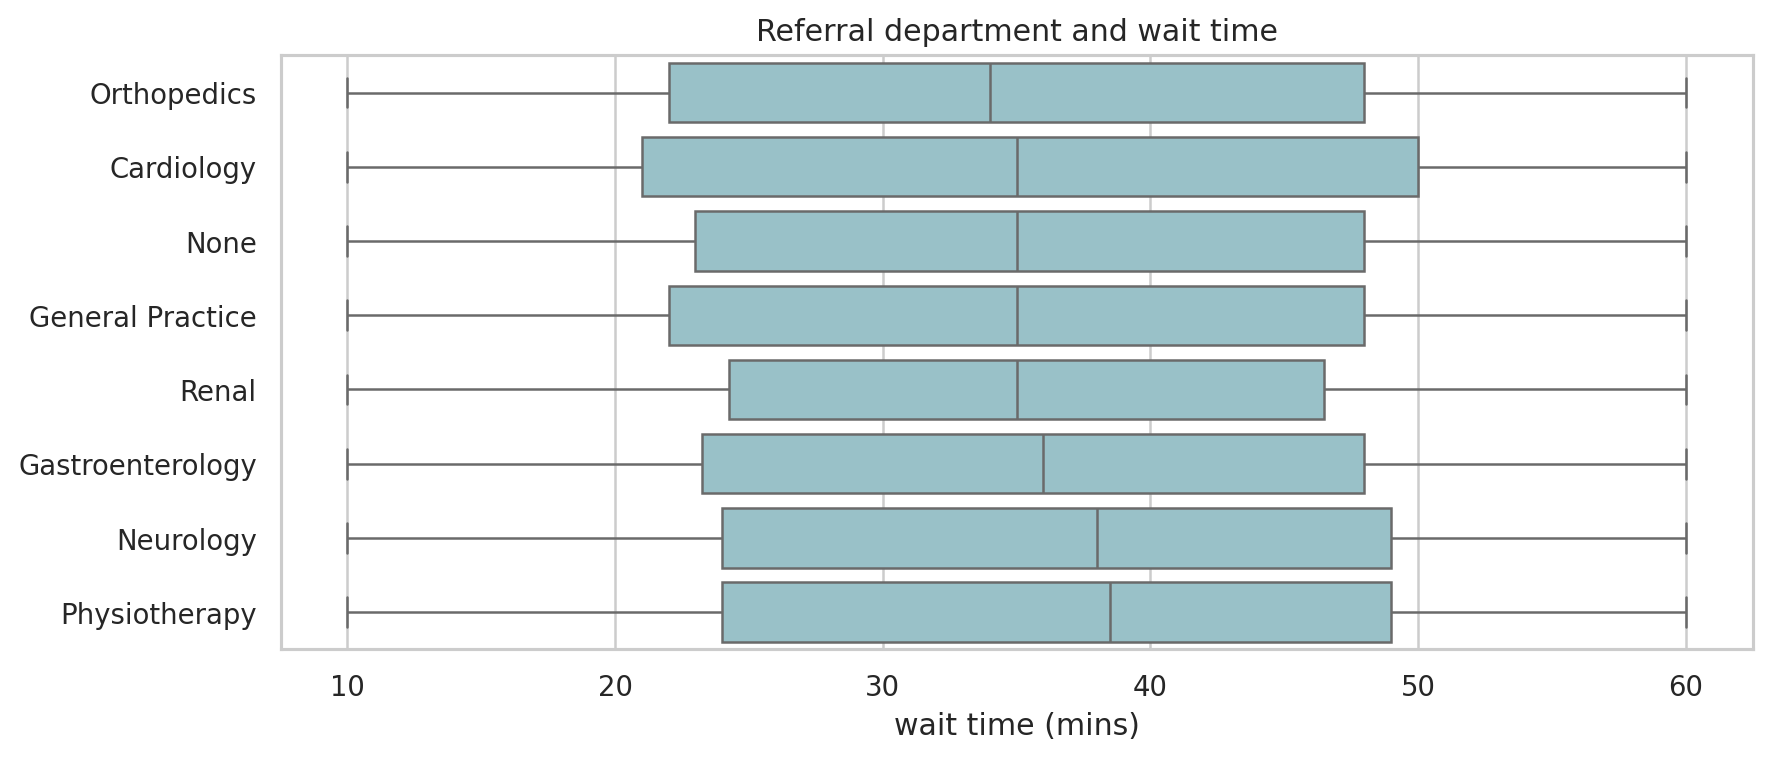

In [18]:
from IPython.display import HTML
import base64
image_path = plot_dir / "05_referral_wait.png"
encoded = base64.b64encode(image_path.read_bytes()).decode("ascii")
HTML(f'<a download="{image_path.name}" href="data:image/png;base64,{encoded}">Download {image_path.name}</a>')

## Admission status and wait time

In [19]:
wait_summary('Patient Admission Flag')

,n,mean,median,std,minimum,maximum
Patient Admission Flag,,,,,,
Admission,4612,34.97,35.0,14.78,10,60
Not Admission,4604,35.55,36.0,14.69,10,60


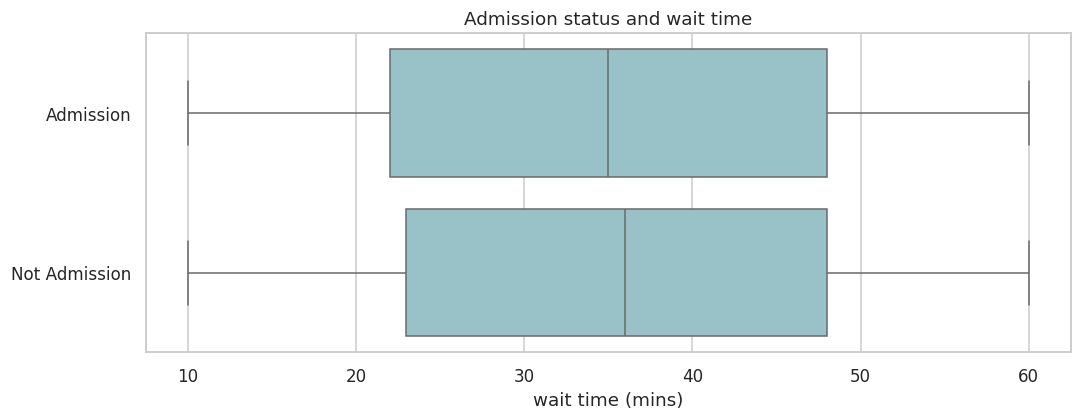

In [20]:
category_plot('Patient Admission Flag', 'Admission status and wait time', '06_admission_wait.png')

**Download this visualization** — run the cell and click its link.

<Download link>
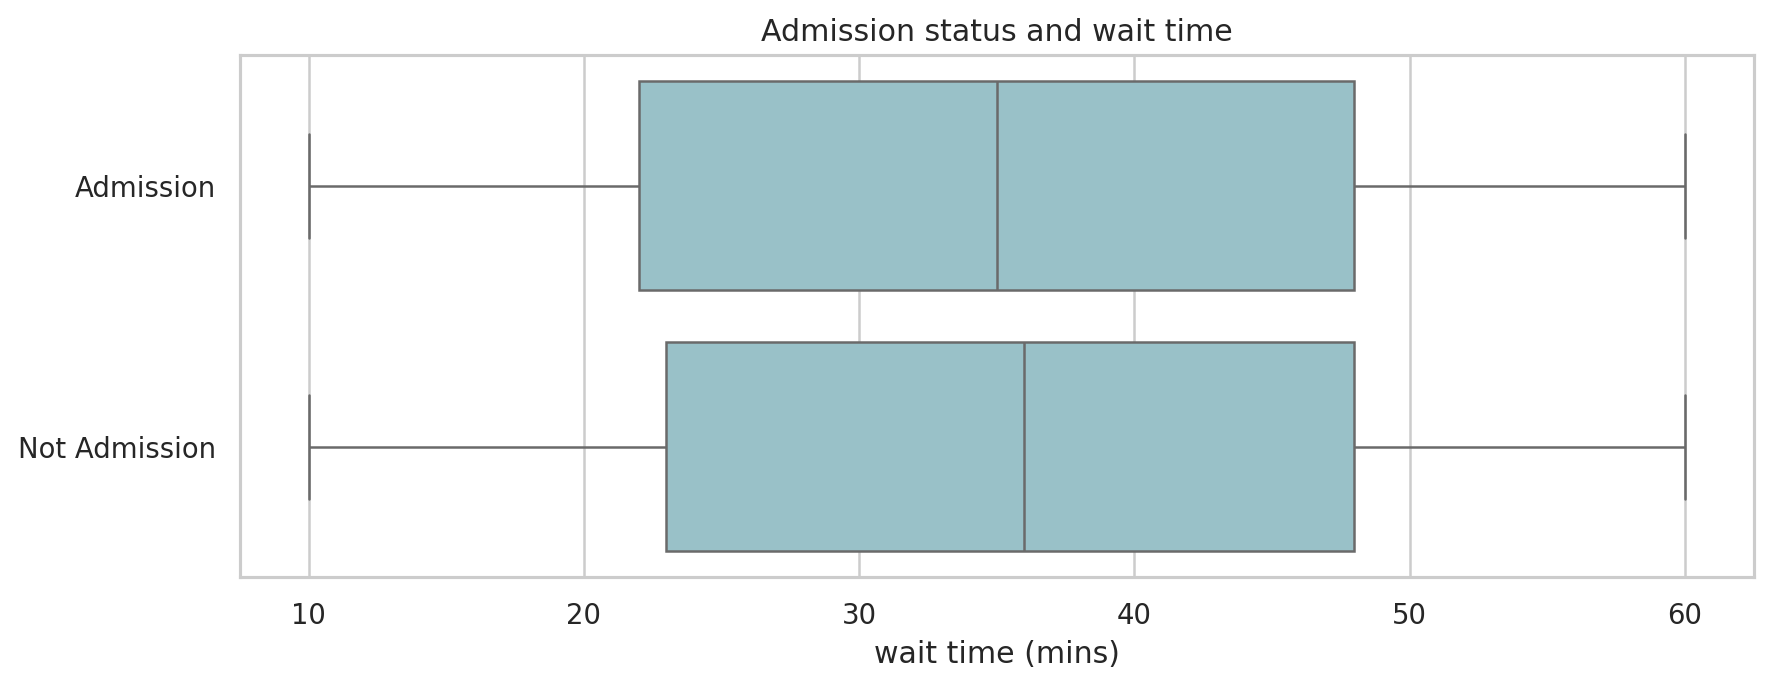

In [21]:
from IPython.display import HTML
import base64
image_path = plot_dir / "06_admission_wait.png"
encoded = base64.b64encode(image_path.read_bytes()).decode("ascii")
HTML(f'<a download="{image_path.name}" href="data:image/png;base64,{encoded}">Download {image_path.name}</a>')

## Compare the size of observed relationships

Eta squared is the fraction of observed wait-time variation associated with between-group differences, without adjusting for other variables. It is descriptive, not causal. Group means can conceal variation within groups; use the boxplots and counts alongside this table.

In [22]:
def eta_squared(column):
    valid = df[[column, "Patient Waittime"]].dropna()
    overall = valid["Patient Waittime"].mean()
    grouped = valid.groupby(column, observed=True)["Patient Waittime"].agg(["size", "mean"])
    total = ((valid["Patient Waittime"] - overall)**2).sum()
    return (grouped["size"] * (grouped["mean"] - overall)**2).sum() / total if total else np.nan

factors = ["Patient Gender", "Age group", "Patient Race", "Department Referral", "Patient Admission Flag"]
effect_summary = pd.DataFrame({"Factor": factors, "Eta squared": [eta_squared(c) for c in factors]})
effect_summary.sort_values("Eta squared", ascending=False).round(5)

,Factor,Eta squared
3,Department Referral,0.00066
4,Patient Admission Flag,0.00039
2,Patient Race,0.00036
1,Age group,0.00015
0,Patient Gender,0.00010


In [23]:
for col in factors:
    stats = wait_summary(col)
    low, high = stats["mean"].idxmin(), stats["mean"].idxmax()
    print(f"{col}: means range from {stats.loc[low, 'mean']:.2f} ({low}) to {stats.loc[high, 'mean']:.2f} ({high}).")
print("Age–wait Pearson r:", round(df["Patient Age"].corr(df["Patient Waittime"]), 4))

Patient Gender: means range from 35.10 (Female) to 35.41 (Male).
Age group: means range from 34.95 (50–64) to 35.46 (0–17).
Patient Race: means range from 34.65 (Pacific Islander) to 35.69 (Native American/Alaska Native).
Department Referral: means range from 34.70 (Renal) to 36.80 (Neurology).
Patient Admission Flag: means range from 34.97 (Admission) to 35.55 (Not Admission).
Age–wait Pearson r: -0.0056


## Findings and interpretation

- Gender: the unclear entries form a separate unknown group (17 records). Compare all three groups in the summary table and boxplot; the unknown group is much smaller, so its average is less stable. No gender is inferred from the unclear source label.
- Age: Pearson and Spearman correlations are both about −0.0056, indicating almost no linear or monotonic association in these records. Age-group means span 34.95–35.46.
- Race: group means span 34.65–35.69; the distributions overlap substantially. This does not establish demographic causes.
- Referral: means span 34.70 for Renal to 36.80 for Neurology. Referral has the largest eta squared among these factors, but it accounts for only about 0.066% of observed wait-time variation. The smaller departments also have fewer observations.
- Admission: admitted records average 34.97 versus 35.55 for not admitted; this is a small descriptive difference, and admission may be determined after waiting.

All five categorical comparisons explain less than 0.1% of wait-time variation individually. These results provide little evidence of a strong unadjusted relationship. They do not rule out interactions or other omitted factors. No predictive performance or causal effect has been established.

## Feature engineering

I created additional features to make the patient information easier to analyse and represent numerically.

- **Age groups:** I grouped patients into 0–17, 18–34, 35–49, 50–64 and 65+ to compare wait times across age ranges.
- **Date and time features:** I extracted the admission hour, weekday, month and year. I also created a weekend indicator, where 1 represents Saturday or Sunday and 0 represents a weekday.
- **Cyclic features:** I used sine and cosine to represent admission hour and weekday. This preserves their repeating patterns, so hours such as 23:00 and 00:00, and days such as Sunday and Monday, are represented as close together.
- **Referral indicator:** I created `Has referral`, where 1 means a department referral was recorded and 0 means the referral category was `None`.
- **Admission indicator:** I encoded `Admission` as 1 and `Not Admission` as 0. I retained this feature in the engineered dataset but left it out of the encoded feature matrix because I could not confirm whether admission status was known before the patient finished waiting.
- **Categorical encoding:** I converted gender, race, referral department and age group into separate 0/1 columns using one-hot encoding. This represents the categories without assigning an artificial ranking. I retained the 17 unclear gender entries as `unknown` rather than assuming a gender.

I excluded patient IDs, patient names and the original gender labels from the encoded feature matrix. I kept `Patient Waittime`, measured in minutes, separately as `y`, and stored the encoded features in `X`. I did not create any features from wait time itself.

In [24]:
features = df.copy()
features["Admission hour"] = features["Patient Admission Time"].map(lambda t: t.hour if pd.notna(t) else np.nan)
features["Admission weekday"] = features["Patient Admission Date"].dt.dayofweek
features["Admission month"] = features["Patient Admission Date"].dt.month
features["Admission year"] = features["Patient Admission Date"].dt.year
features["Weekend admission"] = features["Admission weekday"].ge(5).astype("int64")
features["Hour sin"] = np.sin(2*np.pi*features["Admission hour"]/24)
features["Hour cos"] = np.cos(2*np.pi*features["Admission hour"]/24)
features["Weekday sin"] = np.sin(2*np.pi*features["Admission weekday"]/7)
features["Weekday cos"] = np.cos(2*np.pi*features["Admission weekday"]/7)
features["Has referral"] = features["Department Referral"].ne("None").astype("int64")
features["Admitted"] = features["Patient Admission Flag"].map({"Admission": 1, "Not Admission": 0})
new_columns = ["Age group", "Admission hour", "Admission weekday", "Admission month", "Admission year", "Weekend admission", "Hour sin", "Hour cos", "Weekday sin", "Weekday cos", "Has referral", "Admitted"]
features[new_columns].head()

,Age group,Admission hour,Admission weekday,Admission month,Admission year,Weekend admission,Hour sin,Hour cos,Weekday sin,Weekday cos,Has referral,Admitted
0,50–64,9,0,9,2024,0,0.707107,-0.707107,0.0,1.0,0,0
1,18–34,16,0,9,2024,0,-0.866025,-0.500000,0.0,1.0,1,0
2,65+,0,0,9,2024,0,0.000000,1.000000,0.0,1.0,1,0
3,65+,20,0,9,2024,0,-0.866025,0.500000,0.0,1.0,1,1
4,18–34,19,0,9,2024,0,-0.965926,0.258819,0.0,1.0,0,1


In [25]:
categorical = ["Patient Gender", "Patient Race", "Department Referral", "Age group"]
numeric = ["Patient Age", "Admission month", "Admission year", "Weekend admission", "Hour sin", "Hour cos", "Weekday sin", "Weekday cos", "Has referral"]
# Exclude Admitted by default because its availability at prediction time is unknown.
X = pd.get_dummies(features[numeric + categorical], columns=categorical, dtype=int)
y = features["Patient Waittime"].copy()
assert "Patient Waittime" not in X.columns
assert len(X) == len(df)
print(f"Illustrative predictors: {X.shape[0]:,} rows × {X.shape[1]} columns")
X.head()

Illustrative predictors: 9,216 rows × 32 columns


,Patient Age,Admission month,Admission year,Weekend admission,Hour sin,Hour cos,Weekday sin,Weekday cos,Has referral,Patient Gender_Female,Patient Gender_Male,Patient Gender_unknown,Patient Race_African American,Patient Race_Asian,Patient Race_Declined to Identify,Patient Race_Native American/Alaska Native,Patient Race_Pacific Islander,Patient Race_Two or More Races,Patient Race_White,Department Referral_Cardiology,Department Referral_Gastroenterology,Department Referral_General Practice,Department Referral_Neurology,Department Referral_None,Department Referral_Orthopedics,Department Referral_Physiotherapy,Department Referral_Renal,Age group_0–17,Age group_18–34,Age group_35–49,Age group_50–64,Age group_65+
0,63,9,2024,0,0.707107,-0.707107,0.0,1.0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0
1,31,9,2024,0,-0.866025,-0.500000,0.0,1.0,1,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0
2,75,9,2024,0,0.000000,1.000000,0.0,1.0,1,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,1
3,79,9,2024,0,-0.866025,0.500000,0.0,1.0,1,0,1,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1
4,24,9,2024,0,-0.965926,0.258819,0.0,1.0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0


## Export engineered data and all visualizations

This optional cell writes the enriched dataset, predictor matrix and target locally and creates a ZIP of the six figures. Individual figure downloads remain available above.

In [26]:
import zipfile
features.to_csv("HealthData_Engineered.csv", index=False, date_format="%Y-%m-%d")
X.to_csv("HealthData_Predictors.csv", index=False)
y.to_csv("HealthData_Target.csv", index=False)
with zipfile.ZipFile("EDA_Visualizations.zip", "w", zipfile.ZIP_DEFLATED) as archive:
    for image_path in sorted(plot_dir.glob("*.png")):
        archive.write(image_path, arcname=image_path.name)
print("Exported engineered data and EDA_Visualizations.zip")

Exported engineered data and EDA_Visualizations.zip
